# 02 · ENSO–GMSAT relationship and ENSO-adjusted GMSAT

For each model: how much does ENSO move annual global-mean temperature, does that relationship
differ between ssp245 and SAI, and what does annual GMSAT look like with ENSO removed?

**Method (deliberately simple):**

1. **ENSO index**: relative Niño 3.4 (`nino34_rel`, monthly, from step 01).
2. **Niño anomaly**: relative Niño 3.4 minus its monthly climatology (per model and scenario,
   over `PERIOD`). The relative index has little forced trend, so it is not detrended; section 6
   checks this. The same anomaly is the regressor and the quantity removed in the adjustment.
3. **GMSAT detrended per member**: for each member and scenario, a quadratic in time is fitted
   to calendar-year GMSAT over that scenario's fit window and removed (ssp245: `PERIOD`; SAI:
   from `SAI_SKIP_YEARS` after deployment, because a quadratic cannot follow the fast cooling
   just after deployment). This takes out the forced warming (ssp245) or
   ramp (SAI), which would otherwise swamp the ENSO signal. **For the fit only**, the lagged
   calendar-year Niño anomaly is detrended the same way: detrending GMSAT alone would bias the
   slope low by the fraction of Niño variance the quadratic happens to explain.
4. **Lag.** Niño 3.4 leads GMSAT. The lag (0–12 months) is chosen per model as the one giving
   the highest pooled correlation between calendar-year detrended GMSAT and calendar-year Niño
   anomaly shifted by that lag, unless `choices.enso_adjustment.lag_months` is set.
5. **Fit**: ordinary least squares, detrended GMSAT = a + b × detrended lagged Niño anomaly, over
   each scenario's fit window, pooled across members and scenarios. This pooled slope is used for
   the adjustment. For comparing scenarios, fits are repeated per scenario over the common years
   `COMPARE_PERIOD` (detrended over that window), and slopes compared with a z-test.
6. **Adjustment**: `gmsat_adj = gmsat − b × lagged Niño anomaly` (plain anomaly, not detrended,
   so ENSO variability at all time scales is removed).
7. **First SAI years**: lagged Niño months from before the branch point come from the paired
   ssp245 member (paired scenarios only).

**Excluded**: UKESM1-1 G6-1.5K-SAI (no SST data, and not branched from these ssp245 runs).

Annual means are simple means of 12 months (complete calendar years only).

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

from inputs import load_config, is_configured, open_nc, pairing, deployment_start

CONFIG = os.environ.get("TOE_CONFIG", "inputs.yaml")
IN = Path(os.environ.get("TOE_IN", "interim_outputs/01_indices"))
OUT = Path(os.environ.get("TOE_OUT", "interim_outputs/02_enso"))
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

PERIOD = (2035, 2100)                         # Niño climatology; outer limit of every fit window
SAI_SKIP_YEARS = 5                            # SAI fit windows start this many years after deployment
COMPARE_PERIOD = (2040, 2084)                 # common years for per-scenario fits and difference tests
MAX_LAG = 12                                  # months; Niño 3.4 leading GMSAT
ENSO_INDEX = "nino34_rel"
EXCLUDE = {("UKESM1-1", "G6-1.5K-SAI")}       # no SST; not branched from these ssp245 runs

cfg = load_config(CONFIG)
LAG_CFG = (cfg["choices"].get("enso_adjustment") or {}).get("lag_months")
MODELS = [m for m in cfg["run"]["models"] if is_configured(cfg, m) and (IN / f"{m}_monthly.nc").exists()]
SCENARIOS = [s for s in cfg["run"]["scenarios"] if (cfg["scenarios"][s] or {}).get("kind") in ("baseline", "sai")]
SAI_SCENARIOS = [s for s in SCENARIOS if cfg["scenarios"][s].get("kind") == "sai"]
COLOURS = {"ssp245": "0.3", "G6-1.5K-HiLLA": "#0072B2", "G6-1.5K-SAI": "#D55E00"}
def fit_window(model, scen):
    # Years used for detrending and fitting in the pooled fit
    if cfg["scenarios"][scen].get("kind") != "sai":
        return PERIOD
    dep = deployment_start(cfg, model, scen)
    start = PERIOD[0] if dep is None else max(PERIOD[0], dep // 12 + SAI_SKIP_YEARS)
    return (start, PERIOD[1])

print("models:", MODELS, "| scenarios:", SCENARIOS, "| lag from config:", LAG_CFG)
print("pooled-fit windows:", {(m, s): fit_window(m, s) for m in MODELS for s in SCENARIOS
                              if (m, s) not in EXCLUDE})
print("comparison window:", COMPARE_PERIOD)

models: ['UKESM1-1', 'MIROC-ES2H', 'CESM2-WACCM'] | scenarios: ['ssp245', 'G6-1.5K-HiLLA', 'G6-1.5K-SAI'] | lag from config: None
pooled-fit windows: {('UKESM1-1', 'ssp245'): (2035, 2100), ('UKESM1-1', 'G6-1.5K-HiLLA'): (2040, 2100), ('MIROC-ES2H', 'ssp245'): (2035, 2100), ('MIROC-ES2H', 'G6-1.5K-HiLLA'): (2040, 2100), ('MIROC-ES2H', 'G6-1.5K-SAI'): (2040, 2100), ('CESM2-WACCM', 'ssp245'): (2035, 2100), ('CESM2-WACCM', 'G6-1.5K-HiLLA'): (2040, 2100), ('CESM2-WACCM', 'G6-1.5K-SAI'): (2040, 2100)}
comparison window: (2040, 2084)


## 1. Load monthly GMSAT and relative Niño 3.4

In [2]:
frames = []
for model in MODELS:
    ds = open_nc(str(IN / f"{model}_monthly.nc"))
    for scen in map(str, ds.scenario.values):
        if scen not in SCENARIOS or (model, scen) in EXCLUDE:
            continue
        df = ds.sel(scenario=scen)[["gmsat", ENSO_INDEX]].to_dataframe().reset_index()
        df["ym"] = [t.year * 12 + t.month - 1 for t in df.time]
        df = df.rename(columns={ENSO_INDEX: "nino"})[["member", "ym", "gmsat", "nino"]]
        frames.append(df.dropna(subset=["gmsat", "nino"], how="all").assign(model=model, scenario=scen))
mon = pd.concat(frames, ignore_index=True)
mon["year"], mon["month"] = mon.ym // 12, mon.ym % 12 + 1

# Members with both GMSAT and Niño 3.4 in PERIOD (only these enter the fit)
inp = mon.year.between(*PERIOD)
both = mon.gmsat.notna() & mon.nino.notna()
cov = (mon[inp].groupby(["model", "scenario", "member"])
               .apply(lambda g: pd.Series({"gmsat": g.gmsat.notna().any(), "nino": g.nino.notna().any()}))
               .reset_index())
cov["used"] = cov.gmsat & cov.nino
print("Members contributing to the fit (GMSAT and Niño both present):")
cov.groupby(["model", "scenario"]).apply(
    lambda g: pd.Series({"used": ", ".join(g.member[g.used]) or "-",
                         "missing nino": ", ".join(g.member[g.gmsat & ~g.nino]) or "-"}))

Members contributing to the fit (GMSAT and Niño both present):


/tmp/ipykernel_1913/705642430.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({"gmsat": g.gmsat.notna().any(), "nino": g.nino.notna().any()}))
/tmp/ipykernel_1913/705642430.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cov.groupby(["model", "scenario"]).apply(


used  \
model       scenario                                                          
CESM2-WACCM G6-1.5K-HiLLA                                        r1, r2, r3   
            G6-1.5K-SAI                                          r1, r2, r3   
            ssp245                                               r1, r2, r3   
MIROC-ES2H  G6-1.5K-HiLLA  r01, r02, r03, r04, r05, r06, r07, r08, r09, r10   
            G6-1.5K-SAI    r01, r02, r03, r04, r05, r06, r07, r08, r09, r10   
            ssp245         r01, r02, r03, r04, r05, r06, r07, r08, r09, r10   
UKESM1-1    G6-1.5K-HiLLA                                        r1, r2, r3   
            ssp245                                               r1, r2, r3   

                          missing nino  
model       scenario                    
CESM2-WACCM G6-1.5K-HiLLA            -  
            G6-1.5K-SAI              -  
            ssp245                   -  
MIROC-ES2H  G6-1.5K-HiLLA            -  
            G6-1.5K-SAI              -  
            ssp245                   -  
UKESM1-1    G6-1.5K-HiLLA            -  
            ssp245                   -

## 2. Niño anomaly and detrended GMSAT

- `nino_anom`: relative Niño 3.4 minus its monthly climatology (per model and scenario, over `PERIOD`).
- `g_res`: monthly GMSAT per member minus its monthly climatology and a quadratic in time, over
  the scenario's fit window (NaN outside it). Used only for the monthly diagnostics (example plot, monthly lag curve); the fit itself
  is done on calendar-year values in section 3 onwards.

In [3]:
clim = mon[inp].groupby(["model", "scenario", "month"]).nino.mean().rename("nino_clim")
mon = mon.join(clim, on=["model", "scenario", "month"])
mon["nino_anom"] = mon.nino - mon.nino_clim

def detrend(g):
    # Per member: remove monthly climatology, then a quadratic in time, over the fit window
    g = g.copy()
    g["g_res"] = np.nan
    p = g.year.between(*fit_window(g.model.iloc[0], g.scenario.iloc[0])) & g.gmsat.notna()
    if p.sum() < 36:
        return g
    a = g.gmsat - g.month.map(g[p].groupby("month").gmsat.mean())
    t = (g.ym - g.ym[p].mean()) / 120.0                     # decades, centred
    coef = np.polyfit(t[p], a[p], 2)
    g.loc[p, "g_res"] = (a - np.polyval(coef, t))[p]
    return g

mon = pd.concat([detrend(g) for _, g in mon.groupby(["model", "scenario", "member"])],
                ignore_index=True)

# Source of lagged Niño values: each series, plus up to MAX_LAG pre-branch months from the
# paired ssp245 member for paired SAI scenarios
src = [mon[["model", "scenario", "member", "ym", "nino_anom"]].assign(stitched=False)]
stitch_log = []
for (model, scen, member), g in mon.groupby(["model", "scenario", "member"]):
    if (cfg["scenarios"][scen] or {}).get("kind") != "sai":
        continue
    first = g.loc[g.nino.notna(), "ym"].min()
    if pd.isna(first):
        continue
    n = 0
    if pairing(cfg, model, scen) == "by_member_index":
        base = cfg["scenarios"][scen]["baseline"]
        b = mon[(mon.model == model) & (mon.scenario == base) & (mon.member == member)
                & (mon.ym >= first - MAX_LAG) & (mon.ym < first) & mon.nino.notna()]
        src.append(b[["ym", "nino_anom"]].assign(model=model, scenario=scen, member=member, stitched=True))
        n = len(b)
    stitch_log.append(dict(model=model, scenario=scen, member=member, pairing=pairing(cfg, model, scen),
                           months_borrowed=n))
src = pd.concat(src, ignore_index=True)
stitch_log = pd.DataFrame(stitch_log)
(stitch_log.groupby(["model", "scenario", "pairing"]).months_borrowed
           .agg(lambda s: ", ".join(map(str, sorted(set(s))))))

model        scenario       pairing        
CESM2-WACCM  G6-1.5K-HiLLA  by_member_index    12
             G6-1.5K-SAI    by_member_index    12
MIROC-ES2H   G6-1.5K-HiLLA  by_member_index    12
             G6-1.5K-SAI    by_member_index    12
UKESM1-1     G6-1.5K-HiLLA  by_member_index    12
Name: months_borrowed, dtype: object

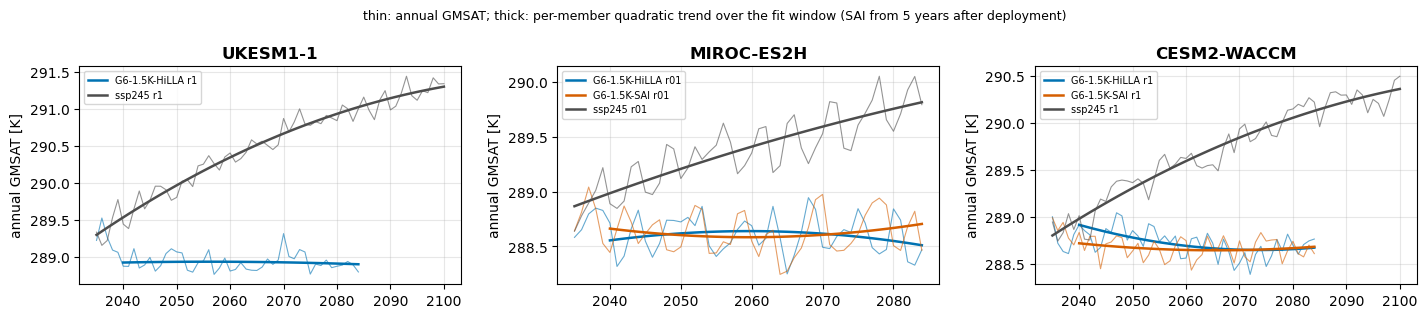

In [4]:
# Detrending, one member per model and scenario: annual GMSAT with its quadratic trend
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 3.2), squeeze=False)
for ax, model in zip(axes[0], MODELS):
    d = mon[(mon.model == model) & mon.year.between(*PERIOD)]
    for scen, g in d.groupby("scenario"):
        mem = sorted(g.member.unique())[0]
        g = g[g.member == mem].groupby("year")[["gmsat", "g_res"]].mean()
        ax.plot(g.index, g.gmsat, color=COLOURS[scen], lw=0.8, alpha=0.6)
        ax.plot(g.index, g.gmsat - g.g_res, color=COLOURS[scen], lw=1.8, label=f"{scen} {mem}")
    ax.set_title(model, fontweight="bold"); ax.set_ylabel("annual GMSAT [K]")
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
fig.suptitle("thin: annual GMSAT; thick: per-member quadratic trend over the fit window (SAI from "
             f"{SAI_SKIP_YEARS} years after deployment)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "detrending_example.png", dpi=150); plt.show()

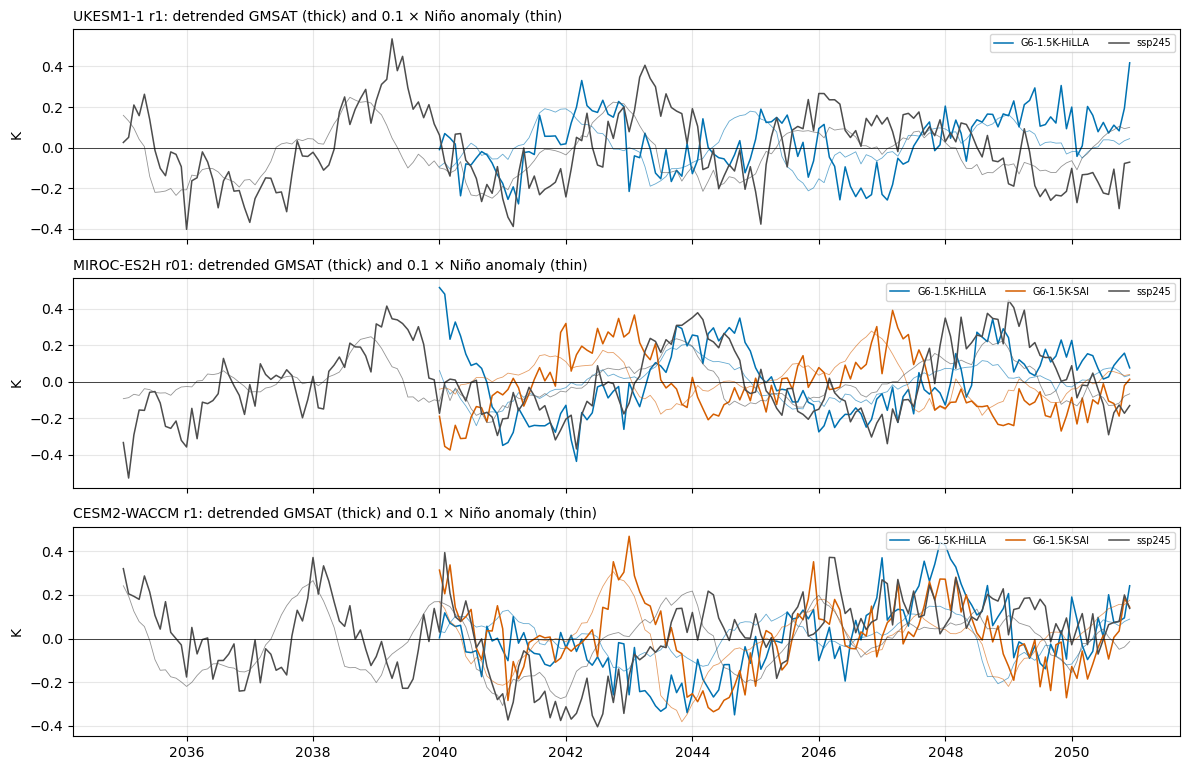

In [5]:
# Example monthly residuals: first member with data, ssp245 and each SAI scenario, 2035-2050
fig, axes = plt.subplots(len(MODELS), 1, figsize=(12, 2.6 * len(MODELS)), squeeze=False, sharex=True)
for ax, model in zip(axes[:, 0], MODELS):
    d = mon[(mon.model == model) & mon.year.between(2035, 2050) & mon.g_res.notna() & mon.nino_anom.notna()]
    if d.empty:
        continue
    mem = d.member.iloc[0]
    for scen, g in d[d.member == mem].groupby("scenario"):
        x = g.ym / 12
        ax.plot(x, g.nino_anom * 0.1, color=COLOURS[scen], lw=0.6, alpha=0.6)
        ax.plot(x, g.g_res, color=COLOURS[scen], lw=1.1, label=scen)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"{model} {mem}: detrended GMSAT (thick) and 0.1 × Niño anomaly (thin)", loc="left", fontsize=10)
    ax.set_ylabel("K")
    ax.legend(fontsize=7, ncol=3, loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "monthly_residuals_example.png", dpi=150); plt.show()

## 3. Choose the lag

lag used (months, Niño leading): {'UKESM1-1': 5, 'MIROC-ES2H': 6, 'CESM2-WACCM': 3} (max annual r)


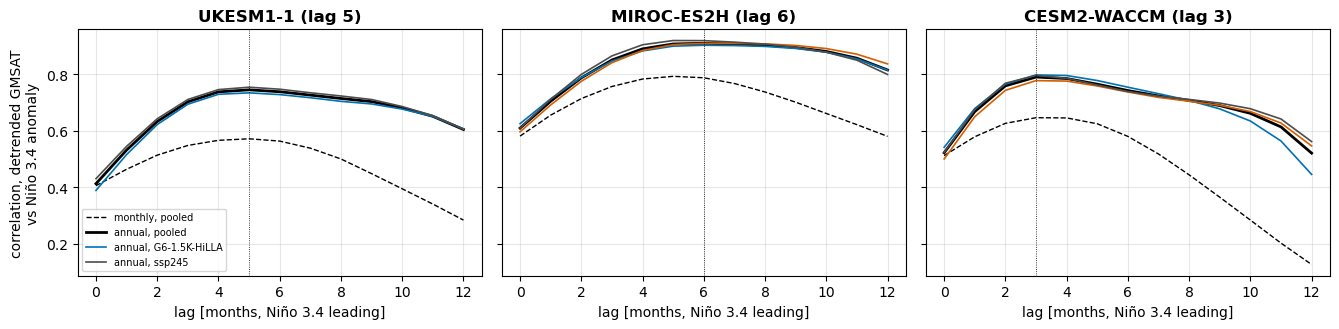

In [6]:
def lagged(L):
    # Monthly table with Niño values from L months earlier
    s = src.drop(columns="stitched").copy()
    s["ym"] = s.ym + L
    s = s.groupby(["model", "scenario", "member", "ym"]).first().reset_index()
    return mon[["model", "scenario", "member", "ym", "year", "gmsat", "g_res"]].merge(
        s, on=["model", "scenario", "member", "ym"], how="left")

def annual(df):
    # Calendar-year means; NaN unless all 12 months present
    cols = ["gmsat", "nino_anom"]
    g = df.groupby(["model", "scenario", "member", "year"])[cols]
    return g.mean().where(g.count() == 12).reset_index()

def detrend_annual(a, window=None):
    # Per member and scenario, over the window (default: the scenario's fit window) and years with
    # both values: remove a quadratic in time from GMSAT (-> y) and the lagged Niño anomaly (-> x).
    out = []
    for (model, scen, _), g in a.groupby(["model", "scenario", "member"]):
        g = g.copy()
        g["y"], g["x"] = np.nan, np.nan
        w = window or fit_window(model, scen)
        q = g.year.between(*w) & g.gmsat.notna() & g.nino_anom.notna()
        if q.sum() >= 10:
            t = g.year - g.year[q].mean()
            for c, new in (("gmsat", "y"), ("nino_anom", "x")):
                coef = np.polyfit(t[q], g[c][q], 2)
                g.loc[q, new] = (g[c] - np.polyval(coef, t))[q]
        out.append(g)
    return pd.concat(out, ignore_index=True)

rows = []
for L in range(MAX_LAG + 1):
    m = lagged(L)
    a = detrend_annual(annual(m))
    for model in MODELS:
        mm = m[(m.model == model) & m.year.between(*PERIOD)].dropna(subset=["g_res", "nino_anom"])
        aa = a[(a.model == model)].dropna(subset=["y", "x"])
        rows.append(dict(model=model, scenario="pooled", lag=L, monthly_r=mm.g_res.corr(mm.nino_anom),
                         annual_r=aa.y.corr(aa.x)))
        for scen, g in aa.groupby("scenario"):
            rows.append(dict(model=model, scenario=scen, lag=L, annual_r=g.y.corr(g.x)))
lagcorr = pd.DataFrame(rows)

pooled = lagcorr[lagcorr.scenario == "pooled"]
LAG = {m: int(LAG_CFG) if LAG_CFG is not None else
       int(pooled[pooled.model == m].set_index("lag").annual_r.idxmax()) for m in MODELS}
print("lag used (months, Niño leading):", LAG, "(from config)" if LAG_CFG is not None else "(max annual r)")

fig, axes = plt.subplots(1, len(MODELS), figsize=(4.5 * len(MODELS), 3.4), squeeze=False, sharey=True)
for ax, model in zip(axes[0], MODELS):
    p = pooled[pooled.model == model]
    ax.plot(p.lag, p.monthly_r, "k--", lw=1, label="monthly, pooled")
    ax.plot(p.lag, p.annual_r, "k-", lw=2, label="annual, pooled")
    for scen, g in lagcorr[(lagcorr.model == model) & (lagcorr.scenario != "pooled")].groupby("scenario"):
        ax.plot(g.lag, g.annual_r, color=COLOURS[scen], lw=1.2, label=f"annual, {scen}")
    ax.axvline(LAG[model], color="k", lw=0.6, ls=":")
    ax.set_title(f"{model} (lag {LAG[model]})", fontweight="bold")
    ax.set_xlabel("lag [months, Niño 3.4 leading]")
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("correlation, detrended GMSAT\nvs Niño 3.4 anomaly")
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "lag_correlation.png", dpi=150); plt.show()

## 4. Fit the relationship

- **pooled**: all members and scenarios, each over its fit window. Used for the adjustment.
- **per scenario** (and `all SAI`, `pooled, common years`): over `COMPARE_PERIOD` for every
  scenario, so that differences between scenarios are not differences between periods.

In [7]:
raw_ann = {m: annual(lagged(LAG[m]))[lambda d, m=m: d.model == m] for m in MODELS}
ann = pd.concat([detrend_annual(raw_ann[m]) for m in MODELS], ignore_index=True)           # fit windows
cmp = pd.concat([detrend_annual(raw_ann[m], COMPARE_PERIOD) for m in MODELS], ignore_index=True)
fitdata = ann.dropna(subset=["y", "x"])
cmpdata = cmp.dropna(subset=["y", "x"])

def fit(d):
    r = stats.linregress(d.x, d.y)
    return dict(slope=r.slope, se=r.stderr, intercept=r.intercept, r=r.rvalue, n_years=len(d),
                n_members=d.member.nunique())

cmp_label = f"{COMPARE_PERIOD[0]}-{COMPARE_PERIOD[1]}"
subsets = {"pooled, common years": lambda d: d, "all SAI": lambda d: d[d.scenario != "ssp245"]}
subsets.update({s: (lambda d, s=s: d[d.scenario == s]) for s in SCENARIOS})
fits = []
for model in MODELS:
    fits.append(dict(model=model, subset="pooled", window="fit windows", lag=LAG[model],
                     **fit(fitdata[fitdata.model == model])))
    d = cmpdata[cmpdata.model == model]
    for name, sel in subsets.items():
        dd = sel(d)
        if len(dd) > 2:
            fits.append(dict(model=model, subset=name, window=cmp_label, lag=LAG[model], **fit(dd)))
fits = pd.DataFrame(fits)
fits.round(4)

,model,subset,window,lag,slope,se,intercept,r,n_years,n_members
0,UKESM1-1,pooled,fit windows,5,0.1158,0.0057,-0.0,0.7443,332,3
1,UKESM1-1,"pooled, common years",2040-2084,5,0.1164,0.0067,0.0,0.7269,269,3
2,UKESM1-1,all SAI,2040-2084,5,0.1221,0.0098,0.0,0.7337,134,3
3,UKESM1-1,ssp245,2040-2084,5,0.1100,0.0092,0.0,0.7201,135,3
4,UKESM1-1,G6-1.5K-HiLLA,2040-2084,5,0.1221,0.0098,0.0,0.7337,134,3
5,MIROC-ES2H,pooled,fit windows,6,0.1695,0.0021,0.0,0.9087,1385,10
6,MIROC-ES2H,"pooled, common years",2040-2084,6,0.1699,0.0021,0.0,0.9089,1335,10
7,MIROC-ES2H,all SAI,2040-2084,6,0.1754,0.0028,0.0,0.9051,885,10
8,MIROC-ES2H,ssp245,2040-2084,6,0.1601,0.0032,0.0,0.9200,450,10
9,MIROC-ES2H,G6-1.5K-HiLLA,2040-2084,6,0.1793,0.0041,0.0,0.9019,435,10


In [8]:
# Does the relationship differ between ssp245 and SAI?  z = (b_SAI - b_ssp245) / sqrt(se_SAI^2 + se_ssp245^2)
tests = []
for model in MODELS:
    f = fits[fits.model == model].set_index("subset")
    if "ssp245" not in f.index:
        continue
    for other in ["all SAI"] + SAI_SCENARIOS:
        if other not in f.index:
            continue
        diff = f.loc[other, "slope"] - f.loc["ssp245", "slope"]
        se = np.hypot(f.loc[other, "se"], f.loc["ssp245", "se"])
        z = diff / se
        tests.append(dict(model=model, comparison=f"{other} vs ssp245", window=cmp_label,
                          slope_ssp245=f.loc["ssp245", "slope"],
                          slope_other=f.loc[other, "slope"], difference=diff, se=se, z=z,
                          p=2 * stats.norm.sf(abs(z))))
tests = pd.DataFrame(tests)
tests.round(4)

,model,comparison,window,slope_ssp245,slope_other,difference,se,z,p
0,UKESM1-1,all SAI vs ssp245,2040-2084,0.1100,0.1221,0.0121,0.0135,0.8985,0.3689
1,UKESM1-1,G6-1.5K-HiLLA vs ssp245,2040-2084,0.1100,0.1221,0.0121,0.0135,0.8985,0.3689
2,MIROC-ES2H,all SAI vs ssp245,2040-2084,0.1601,0.1754,0.0153,0.0043,3.5986,0.0003
3,MIROC-ES2H,G6-1.5K-HiLLA vs ssp245,2040-2084,0.1601,0.1793,0.0192,0.0052,3.6662,0.0002
4,MIROC-ES2H,G6-1.5K-SAI vs ssp245,2040-2084,0.1601,0.1717,0.0116,0.0049,2.3650,0.0180
5,CESM2-WACCM,all SAI vs ssp245,2040-2084,0.1084,0.0992,-0.0092,0.0083,-1.1012,0.2708
6,CESM2-WACCM,G6-1.5K-HiLLA vs ssp245,2040-2084,0.1084,0.1000,-0.0085,0.0095,-0.8901,0.3734
7,CESM2-WACCM,G6-1.5K-SAI vs ssp245,2040-2084,0.1084,0.0983,-0.0101,0.0097,-1.0367,0.2999


The z-test treats annual values as independent and the two slopes as independent. Year-to-year
persistence, and the degrees of freedom used by the per-member trend fits, both make the true
uncertainty somewhat larger than the OLS standard errors, so read p-values near 0.05 with caution.

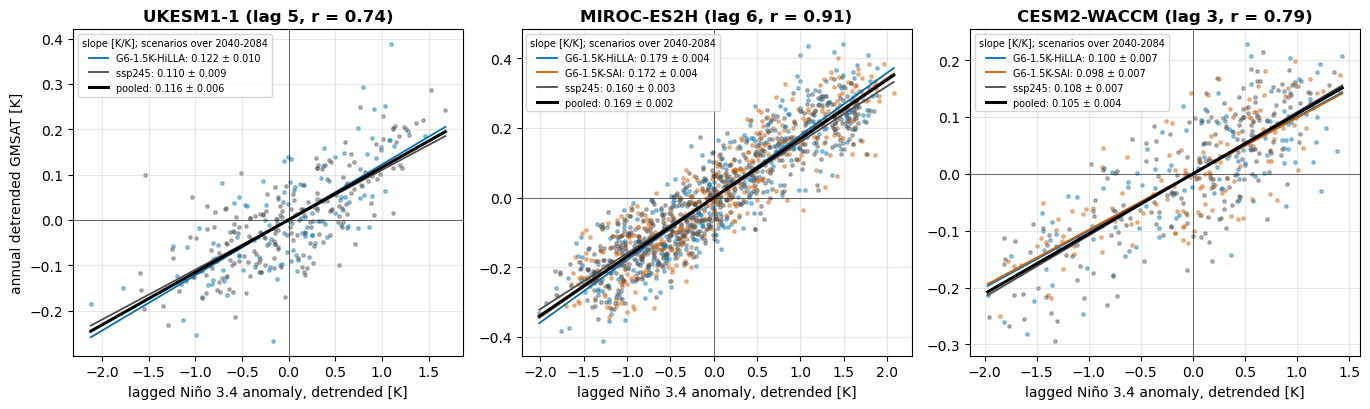

In [9]:
# Scatter: annual GMSAT residual vs lagged Niño residual, with pooled and per-scenario fits
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4.2), squeeze=False)
for ax, model in zip(axes[0], MODELS):
    d = fitdata[fitdata.model == model]
    xs = np.linspace(d.x.min(), d.x.max(), 10)
    for scen, g in d.groupby("scenario"):
        ax.scatter(g.x, g.y, s=6, alpha=0.4, color=COLOURS[scen])
        f = fits[(fits.model == model) & (fits.subset == scen)].iloc[0]
        ax.plot(xs, f.intercept + f.slope * xs, color=COLOURS[scen], lw=1.3,
                label=f"{scen}: {f.slope:.3f} ± {f.se:.3f}")
    f = fits[(fits.model == model) & (fits.subset == "pooled")].iloc[0]
    ax.plot(xs, f.intercept + f.slope * xs, "k", lw=2.2, label=f"pooled: {f.slope:.3f} ± {f.se:.3f}")
    ax.axhline(0, color="k", lw=0.4); ax.axvline(0, color="k", lw=0.4)
    ax.set_title(f"{model} (lag {LAG[model]}, r = {f.r:.2f})", fontweight="bold")
    ax.set_xlabel("lagged Niño 3.4 anomaly, detrended [K]")
    ax.legend(fontsize=7, title=f"slope [K/K]; scenarios over {cmp_label}", title_fontsize=7)
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("annual detrended GMSAT [K]")
fig.tight_layout(); fig.savefig(FIG / "scatter_fits.png", dpi=150); plt.show()

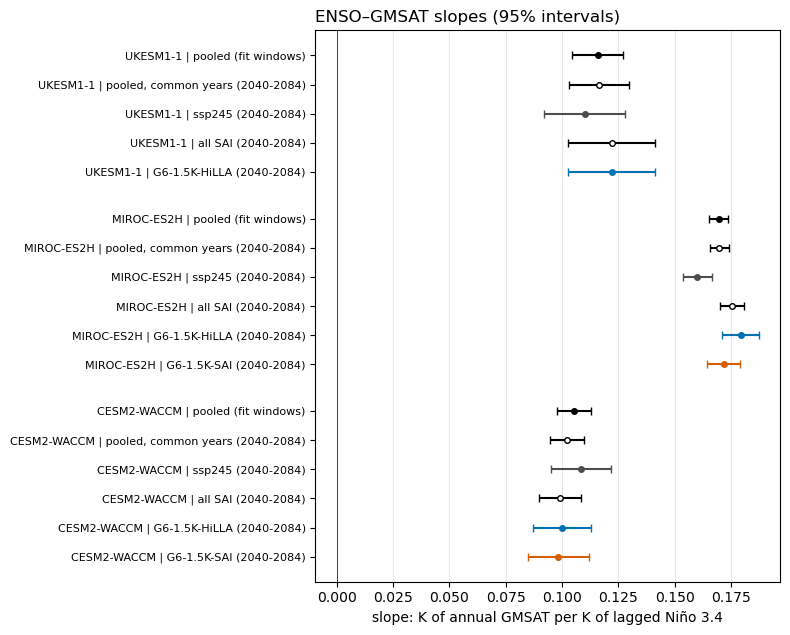

In [10]:
# Slopes with 95% intervals (± 1.96 se), per model and subset
order = ["pooled", "pooled, common years", "ssp245", "all SAI"] + SAI_SCENARIOS
fig, ax = plt.subplots(figsize=(8, 0.5 + 0.35 * len(fits)))
y, ticks, labels = 0, [], []
for model in MODELS:
    for name in order:
        f = fits[(fits.model == model) & (fits.subset == name)]
        if f.empty:
            continue
        f = f.iloc[0]
        c = COLOURS.get(name, "k")
        ax.errorbar(f.slope, y, xerr=1.96 * f.se, fmt="o", color=c, ms=4, capsize=3,
                    mfc="white" if name in ("all SAI", "pooled, common years") else c)
        ticks.append(y); labels.append(f"{model} | {name} ({f.window})")
        y -= 1
    y -= 0.6
ax.set_yticks(ticks, labels, fontsize=8)
ax.set_xlabel("slope: K of annual GMSAT per K of lagged Niño 3.4")
ax.axvline(0, color="k", lw=0.5)
ax.grid(axis="x", alpha=0.3)
ax.set_title("ENSO–GMSAT slopes (95% intervals)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "slopes.png", dpi=150); plt.show()

## 5. ENSO-adjusted annual GMSAT

`gmsat_adj = gmsat − b_pooled × lagged Niño anomaly`, applied to every year with a complete lagged
Niño value (not only `PERIOD`). Years without one (e.g. members with no SST) stay NaN.

In [11]:
B = fits[fits.subset == "pooled"].set_index("model").slope.to_dict()
ann["slope"] = ann.model.map(B)
ann["gmsat_adj"] = ann.gmsat - ann.slope * ann.nino_anom
ann["y_adj"] = ann.y - ann.slope * ann.x

# Interannual noise before/after: std of detrended annual GMSAT over each scenario's fit window
p = ann.dropna(subset=["y", "y_adj"])
noise = (p.groupby(["model", "scenario"])
          .apply(lambda g: pd.Series({"std_raw": g.y.std(), "std_adj": g.y_adj.std()})))
noise["reduction_%"] = 100 * (1 - noise.std_adj / noise.std_raw)
noise.round(4)

/tmp/ipykernel_1913/1439677488.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({"std_raw": g.y.std(), "std_adj": g.y_adj.std()})))


std_raw  std_adj  reduction_%
model       scenario                                    
CESM2-WACCM G6-1.5K-HiLLA   0.1069   0.0647      39.4481
            G6-1.5K-SAI     0.0961   0.0608      36.7951
            ssp245          0.1117   0.0681      39.0500
MIROC-ES2H  G6-1.5K-HiLLA   0.1780   0.0774      56.5240
            G6-1.5K-SAI     0.1720   0.0718      58.2502
            ssp245          0.1671   0.0668      60.0290
UKESM1-1    G6-1.5K-HiLLA   0.1106   0.0753      31.9496
            ssp245          0.1029   0.0677      34.2205

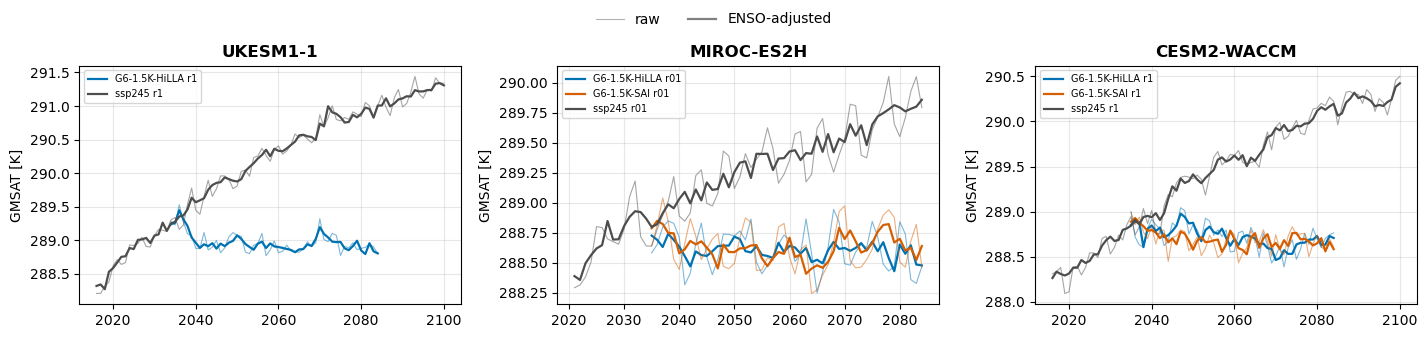

In [12]:
# Raw vs adjusted annual GMSAT, first member with Niño data, each scenario
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 3.4), squeeze=False, sharey=False)
for ax, model in zip(axes[0], MODELS):
    d = ann[(ann.model == model) & ann.gmsat_adj.notna()]
    for scen, g in d.groupby("scenario"):
        mem = sorted(g.member.unique())[0]
        g = g[g.member == mem]
        ax.plot(g.year, g.gmsat, color=COLOURS[scen], lw=0.8, alpha=0.5)
        ax.plot(g.year, g.gmsat_adj, color=COLOURS[scen], lw=1.6, label=f"{scen} {mem}")
    ax.set_title(model, fontweight="bold"); ax.set_ylabel("GMSAT [K]")
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
fig.legend([Line2D([], [], color="0.5", lw=0.8, alpha=0.6), Line2D([], [], color="0.5", lw=1.6)],
           ["raw", "ENSO-adjusted"], loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(FIG / "gmsat_raw_vs_adjusted.png", dpi=150); plt.show()

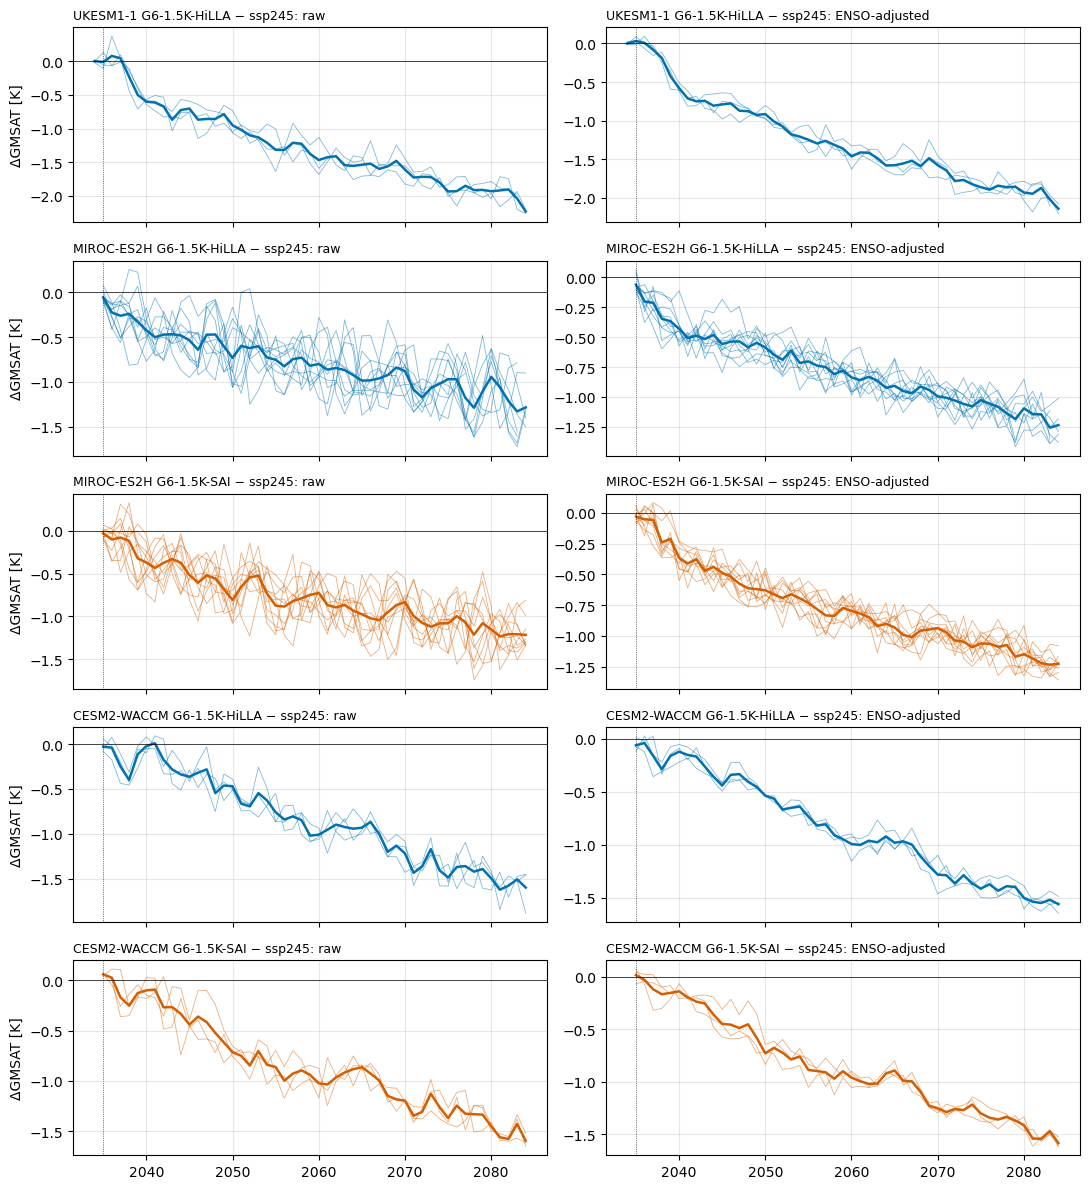

In [13]:
# Paired SAI - ssp245 differences (paired scenarios only), raw vs adjusted: thin = members, thick = mean
pairs = [(m, s) for m in MODELS for s in SAI_SCENARIOS
         if (m, s) not in EXCLUDE and pairing(cfg, m, s) == "by_member_index"]
fig, axes = plt.subplots(len(pairs), 2, figsize=(11, 2.4 * len(pairs)), squeeze=False, sharex=True)
for (model, scen), row in zip(pairs, axes):
    d = ann[ann.model == model].pivot_table(index="year", columns=["scenario", "member"],
                                            values=["gmsat", "gmsat_adj"])
    for ax, var, title in ((row[0], "gmsat", "raw"), (row[1], "gmsat_adj", "ENSO-adjusted")):
        if scen not in d[var].columns.get_level_values(0):
            continue
        diff = (d[var][scen] - d[var]["ssp245"]).dropna(how="all")
        for mem in diff.columns:
            ax.plot(diff.index, diff[mem], color=COLOURS[scen], lw=0.6, alpha=0.5)
        ax.plot(diff.index, diff.mean(axis=1), color=COLOURS[scen], lw=1.8)
        dep = deployment_start(cfg, model, scen)
        if dep is not None:
            ax.axvline(dep / 12, color="k", lw=0.5, ls=":")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_title(f"{model} {scen} − ssp245: {title}", loc="left", fontsize=9)
        ax.grid(alpha=0.3)
    row[0].set_ylabel("ΔGMSAT [K]")
fig.tight_layout(); fig.savefig(FIG / "paired_differences_raw_vs_adjusted.png", dpi=150); plt.show()

## 6. Check: does the relative Niño 3.4 index drift?

The adjustment subtracts `b × (Niño − its climatology)`. If the scenario-mean relative index
trends over time, part of the forced signal would be removed along with ENSO. The ensemble-mean
annual anomaly should stay near zero.

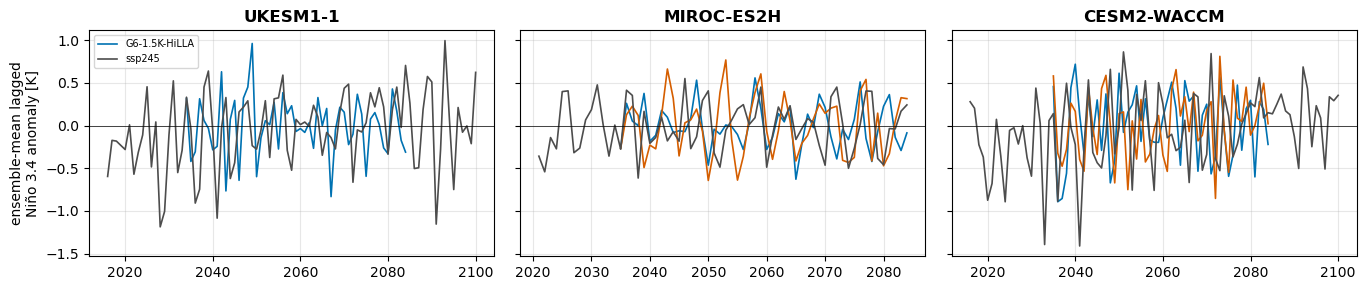

Trend in the ensemble-mean relative Niño anomaly over PERIOD, and the GMSAT trend it would
introduce through the adjustment (slope x trend):


,model,scenario,trend_K_per_century,trend_se,gmsat_effect_K_per_century
0,UKESM1-1,G6-1.5K-HiLLA,-0.0400,0.3492,-0.0046
1,UKESM1-1,ssp245,0.3737,0.2809,0.0433
2,MIROC-ES2H,G6-1.5K-HiLLA,-0.1309,0.2495,-0.0222
3,MIROC-ES2H,G6-1.5K-SAI,0.0389,0.3461,0.0066
4,MIROC-ES2H,ssp245,0.0384,0.2934,0.0065
5,CESM2-WACCM,G6-1.5K-HiLLA,0.0738,0.4136,0.0078
6,CESM2-WACCM,G6-1.5K-SAI,0.4947,0.3862,0.0521
7,CESM2-WACCM,ssp245,0.5171,0.2780,0.0545


In [14]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3), squeeze=False, sharey=True)
drift = []
for ax, model in zip(axes[0], MODELS):
    d = ann[(ann.model == model) & ann.nino_anom.notna()]
    for scen, g in d.groupby("scenario"):
        em = g.groupby("year").nino_anom.mean()
        ax.plot(em.index, em.values, color=COLOURS[scen], lw=1.2, label=scen)
        e = em[em.index.to_series().between(*PERIOD)]
        if len(e) > 2:
            t = stats.linregress(e.index, e.values)
            drift.append(dict(model=model, scenario=scen, trend_K_per_century=100 * t.slope,
                              trend_se=100 * t.stderr, gmsat_effect_K_per_century=100 * t.slope * B[model]))
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(model, fontweight="bold"); ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("ensemble-mean lagged\nNiño 3.4 anomaly [K]")
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "nino_drift.png", dpi=150); plt.show()
print("Trend in the ensemble-mean relative Niño anomaly over PERIOD, and the GMSAT trend it would")
print("introduce through the adjustment (slope x trend):")
pd.DataFrame(drift).round(4)

## 7. Save

In [15]:
for model in MODELS:
    d = ann[ann.model == model].set_index(["scenario", "member", "year"])
    ds = xr.Dataset({
        "gmsat": d.gmsat.to_xarray(),
        "gmsat_adj": d.gmsat_adj.to_xarray(),
        "nino_anom_lagged": d.nino_anom.to_xarray(),
    })
    scen_order = [s for s in SCENARIOS if s in ds.scenario.values]
    ds = ds.reindex(scenario=scen_order)
    ds.gmsat.attrs.update(units="K", long_name="calendar-year mean GMSAT")
    ds.gmsat_adj.attrs.update(units="K", long_name="calendar-year GMSAT minus slope x lagged Nino3.4 anomaly")
    ds.nino_anom_lagged.attrs.update(units="K", long_name=f"calendar-year mean {ENSO_INDEX} anomaly, lagged")
    f = fits[(fits.model == model) & (fits.subset == "pooled")].iloc[0]
    ds.attrs.update(model=model, enso_index=ENSO_INDEX, lag_months=int(LAG[model]),
                    slope_K_per_K=float(f.slope), slope_se=float(f.se), r=float(f.r),
                    fit_windows=str({s: f"{w[0]}-{w[1]}" for s in scen_order
                                     for w in [fit_window(model, s)]}),
                    compare_period=cmp_label,
                    excluded=str(sorted(s for m, s in EXCLUDE if m == model)),
                    method="OLS of calendar-year GMSAT on lagged calendar-year Nino3.4 anomaly "
                           "(minus monthly climatology), both with a per-member quadratic in time "
                           "removed over fit_period, pooled across members and scenarios; "
                           "gmsat_adj = gmsat - slope x (plain, undetrended) lagged anomaly")
    ds.to_netcdf(OUT / f"{model}_gmsat_enso_adjusted.nc")

fits.to_csv(OUT / "enso_fits.csv", index=False)
tests.to_csv(OUT / "slope_difference_tests.csv", index=False)
lagcorr.to_csv(OUT / "lag_correlations.csv", index=False)
noise.to_csv(OUT / "noise_reduction.csv")
stitch_log.to_csv(OUT / "stitch_log.csv", index=False)
print("written:", sorted(p.name for p in OUT.glob("*.*")))

written: ['CESM2-WACCM_gmsat_enso_adjusted.nc', 'MIROC-ES2H_gmsat_enso_adjusted.nc', 'UKESM1-1_gmsat_enso_adjusted.nc', 'enso_fits.csv', 'lag_correlations.csv', 'noise_reduction.csv', 'slope_difference_tests.csv', 'stitch_log.csv']


In [16]:
### not part of main pipeline - just to check miroc incomplete files:

# Last month with data, per MIROC index, scenario and member (from the step 01 monthly file)
from inputs import open_nc
MODEL = "MIROC-ES2H"
ds = open_nc(str(IN / f"{MODEL}_monthly.nc"))
rows = []
for v in ds.data_vars:
    for scen in map(str, ds.scenario.values):
        for mem in map(str, ds.member.values):
            s = ds[v].sel(scenario=scen, member=mem)
            ok = s.notnull().values
            if ok.any():
                t = s.time.values[ok][-1]
                rows.append(dict(scenario=scen, member=mem, index=v, last=f"{t.year}-{t.month:02d}"))
end = pd.DataFrame(rows)
end["scenario_end"] = end.groupby(["scenario", "index"])["last"].transform("max")
short = end[end["last"] < end["scenario_end"]]
print("Members ending before the rest of their scenario:")
print(short.pivot_table(index=["scenario", "member"], columns="index", values="last", aggfunc="first")
      .fillna("full").to_string() if len(short) else "  none")
end.pivot_table(index=["scenario", "member"], columns="index", values="last", aggfunc="first")

Members ending before the rest of their scenario:
index                   gmsat      ism   nino34 nino34_rel   sia_nh trop_sst
scenario      member                                                        
G6-1.5K-HiLLA r02     2083-12  2083-12  2083-12    2083-12  2084-04  2083-12
              r04     2077-12  2077-12     full       full  2077-12     full
              r05     2083-12  2083-12  2083-12    2083-12  2084-10  2083-12
              r06     2079-12  2079-12     full       full  2079-12     full
              r10     2083-12  2083-12  2083-12    2083-12  2084-04  2083-12


index                   gmsat      ism   nino34 nino34_rel   sia_nh trop_sst
scenario      member                                                        
G6-1.5K-HiLLA r01     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r02     2083-12  2083-12  2083-12    2083-12  2084-04  2083-12
              r03     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r04     2077-12  2077-12  2084-12    2084-12  2077-12  2084-12
              r05     2083-12  2083-12  2083-12    2083-12  2084-10  2083-12
              r06     2079-12  2079-12  2084-12    2084-12  2079-12  2084-12
              r07     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r08     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r09     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r10     2083-12  2083-12  2083-12    2083-12  2084-04  2083-12
G6-1.5K-SAI   r01     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r02     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r03     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r04     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r05     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r06     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r07     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r08     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r09     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r10     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
ssp245        r01     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r02     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r03     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r04     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r05     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r06     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r07     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r08     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r09     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12
              r10     2084-12  2084-12  2084-12    2084-12  2084-12  2084-12